# Currency Exchange Rate vs Flight Operations Analysis
This notebook analyzes correlations between NOK/EUR exchange rates and various flight operations metrics.

**Objective**: Discover how currency fluctuations might impact:
- Flight volumes (number of flights)
- Flight delays and punctuality 
- Route popularity and demand
- Seasonal patterns
- Airport-specific impacts

**Data Sources**: 
- Historical flight data (410K+ flights, 2018-2025)
- NOK/EUR exchange rates (monthly/quarterly data)
- Airport and route information

**Analysis Approach**:
1. Load and prepare currency + flight data
2. Merge datasets by time periods
3. Correlation analysis across multiple dimensions
4. Visualization of trends and patterns
5. Statistical significance testing

In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from pathlib import Path
import warnings
from scipy import stats
from scipy.stats import pearsonr, spearmanr
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

warnings.filterwarnings("ignore")

# Set up plotting
plt.style.use("default")
sns.set_palette("husl")
fig_size = (12, 8)

print("📚 Libraries imported successfully")
print(f"🕐 Current time: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

# Data paths
data_path = Path("../data")
print(f"📁 Data directory: {data_path}")

# Check available data files
available_files = list(data_path.glob("*.csv"))
print(f"\n📊 Available data files:")
for file in available_files:
    size_mb = file.stat().st_size / (1024 * 1024)
    print(f"   • {file.name}: {size_mb:.1f} MB")

📚 Libraries imported successfully
🕐 Current time: 2025-09-15 14:15:07
📁 Data directory: ..\data

📊 Available data files:
   • airportgroups.csv: 0.0 MB
   • airport_coordinates.csv: 0.0 MB
   • airport_locations.csv: 0.0 MB
   • historical_flights.csv: 50.4 MB
   • nok_eur_monthly.csv: 0.0 MB
   • nok_eur_quarterly.csv: 0.0 MB
   • schedule_oct2025.csv: 0.3 MB
   • weather_data_test.csv: 0.2 MB


In [ ]:
# Load historical flight data
print("✈️ LOADING HISTORICAL FLIGHT DATA")
print("=" * 50)

flights_file = data_path / "avinor_data/historical_flights.csv"
df_flights = pd.read_csv(flights_file)

print(f"✅ Loaded {len(df_flights):,} flight records")
print(f"📅 Date range: {df_flights['std'].min()} to {df_flights['std'].max()}")
print(f"🗂️ Columns: {list(df_flights.columns)}")

# Convert datetime columns
datetime_cols = ["std", "atd", "sta", "ata"]
for col in datetime_cols:
    if col in df_flights.columns:
        df_flights[col] = pd.to_datetime(df_flights[col], errors="coerce")

print(f"\n📊 Flight data overview:")
print(f"   • Departure airports: {df_flights['dep_airport'].nunique()}")
print(f"   • Arrival airports: {df_flights['arr_airport'].nunique()}")
print(
    f"   • Airlines: {df_flights['airline'].nunique() if 'airline' in df_flights.columns else 'N/A'}"
)
print(
    f"   • Aircraft types: {df_flights['aircraft_type'].nunique() if 'aircraft_type' in df_flights.columns else 'N/A'}"
)

# Load currency data
print(f"\n💱 LOADING CURRENCY DATA")
print("=" * 30)

# Try to load currency data (both monthly and quarterly)
currency_files = {
    "monthly": data_path / "nok_eur_monthly.csv",
    "quarterly": data_path / "nok_eur_quarterly.csv",
}

currency_data = {}
for period, file_path in currency_files.items():
    if file_path.exists():
        df_currency = pd.read_csv(file_path)

        # Handle different column structures
        if period == "monthly":
            if "date" in df_currency.columns:
                df_currency["date"] = pd.to_datetime(df_currency["date"])
                currency_data[period] = df_currency
                print(f"✅ Loaded {period} currency data: {len(df_currency)} records")
                print(
                    f"   • Date range: {df_currency['date'].min().strftime('%Y-%m-%d')} to {df_currency['date'].max().strftime('%Y-%m-%d')}"
                )
                print(
                    f"   • Exchange rate range: {df_currency['nok_to_eur'].min():.6f} to {df_currency['nok_to_eur'].max():.6f}"
                )
            else:
                print(f"⚠️ Monthly currency file missing 'date' column")
        elif period == "quarterly":
            if "quarter_start" in df_currency.columns:
                df_currency["date"] = pd.to_datetime(df_currency["quarter_start"])
                currency_data[period] = df_currency
                print(f"✅ Loaded {period} currency data: {len(df_currency)} records")
                print(
                    f"   • Date range: {df_currency['date'].min().strftime('%Y-%m-%d')} to {df_currency['date'].max().strftime('%Y-%m-%d')}"
                )
                print(
                    f"   • Exchange rate range: {df_currency['avg_nok_to_eur'].min():.6f} to {df_currency['avg_nok_to_eur'].max():.6f}"
                )
            else:
                print(f"⚠️ Quarterly currency file missing expected columns")
    else:
        print(f"⚠️ {period.title()} currency file not found: {file_path}")

if not currency_data:
    print(
        "❌ No currency data found! Please run the currency data collection notebook first."
    )
else:
    print(
        f"\n🎯 Ready for correlation analysis with {len(currency_data)} currency datasets"
    )

✈️ LOADING HISTORICAL FLIGHT DATA
✅ Loaded 410,442 flight records
📅 Date range: 2018-01-01T07:20:00.000000 to 2025-07-31T21:40:00.000000
🗂️ Columns: ['flight_id', 'dep_airport', 'dep_airport_group', 'arr_airport', 'arr_airport_group', 'service_type', 'std', 'sta', 'cancelled', 'atd', 'ata']
✅ Loaded 410,442 flight records
📅 Date range: 2018-01-01T07:20:00.000000 to 2025-07-31T21:40:00.000000
🗂️ Columns: ['flight_id', 'dep_airport', 'dep_airport_group', 'arr_airport', 'arr_airport_group', 'service_type', 'std', 'sta', 'cancelled', 'atd', 'ata']

📊 Flight data overview:
   • Departure airports: 118
   • Arrival airports: 122
   • Airlines: N/A
   • Aircraft types: N/A

💱 LOADING CURRENCY DATA
✅ Loaded monthly currency data: 93 records
   • Date range: 2018-01-01 to 2025-09-01
   • Exchange rate range: 0.083560 to 0.105860
✅ Loaded quarterly currency data: 31 records
   • Date range: 2018-01-01 to 2025-07-01
   • Exchange rate range: 0.084773 to 0.104543

🎯 Ready for correlation analysis 

In [ ]:
# Create comprehensive flight metrics for correlation analysis
print("📊 CREATING FLIGHT METRICS FOR ANALYSIS")
print("=" * 50)

# Add time dimensions to flight data
df_flights["year"] = df_flights["std"].dt.year
df_flights["month"] = df_flights["std"].dt.month
df_flights["quarter"] = df_flights["std"].dt.quarter
df_flights["year_month"] = df_flights["std"].dt.to_period("M")
df_flights["year_quarter"] = df_flights["std"].dt.to_period("Q")
df_flights["weekday"] = df_flights["std"].dt.weekday
df_flights["is_weekend"] = df_flights["weekday"].isin([5, 6])

# Calculate delay metrics
print("⏰ Calculating delay metrics...")
if "atd" in df_flights.columns and "std" in df_flights.columns:
    df_flights["departure_delay_minutes"] = (
        df_flights["atd"] - df_flights["std"]
    ).dt.total_seconds() / 60
    df_flights["departure_delay_minutes"] = df_flights[
        "departure_delay_minutes"
    ].fillna(0)
    df_flights["is_departure_delayed"] = df_flights["departure_delay_minutes"] > 15

if "ata" in df_flights.columns and "sta" in df_flights.columns:
    df_flights["arrival_delay_minutes"] = (
        df_flights["ata"] - df_flights["sta"]
    ).dt.total_seconds() / 60
    df_flights["arrival_delay_minutes"] = df_flights["arrival_delay_minutes"].fillna(0)
    df_flights["is_arrival_delayed"] = df_flights["arrival_delay_minutes"] > 15

# Create route information
df_flights["route"] = df_flights["dep_airport"] + "-" + df_flights["arr_airport"]
df_flights["is_domestic"] = (
    df_flights["dep_airport_group"] == df_flights["arr_airport_group"]
)
df_flights["is_international"] = ~df_flights["is_domestic"]

print("✅ Flight metrics created:")
delay_cols = [col for col in df_flights.columns if "delay" in col]
print(f"   • Delay metrics: {delay_cols}")
print(f"   • Route information: route, is_domestic, is_international")
print(f"   • Time dimensions: year, month, quarter, weekday, is_weekend")

# Create monthly flight aggregations
print(f"\n📈 Creating monthly flight aggregations...")
monthly_flights = (
    df_flights.groupby(["year", "month"])
    .agg(
        {
            "flight_id": "count",  # Total flights
            "departure_delay_minutes": [
                "mean",
                "median",
                "std",
                lambda x: (x > 15).sum(),
            ],
            "arrival_delay_minutes": [
                "mean",
                "median",
                "std",
                lambda x: (x > 15).sum(),
            ],
            "is_departure_delayed": "mean",
            "is_arrival_delayed": "mean",
            "is_domestic": "sum",
            "is_international": "sum",
            "is_weekend": "mean",
            "route": "nunique",
            "dep_airport": "nunique",
            "arr_airport": "nunique",
        }
    )
    .round(3)
)

# Flatten column names
monthly_flights.columns = [
    "total_flights",
    "avg_dep_delay",
    "median_dep_delay",
    "std_dep_delay",
    "delayed_departures",
    "avg_arr_delay",
    "median_arr_delay",
    "std_arr_delay",
    "delayed_arrivals",
    "pct_dep_delayed",
    "pct_arr_delayed",
    "domestic_flights",
    "international_flights",
    "pct_weekend_flights",
    "unique_routes",
    "unique_dep_airports",
    "unique_arr_airports",
]

monthly_flights = monthly_flights.reset_index()
monthly_flights["date"] = pd.to_datetime(
    monthly_flights[["year", "month"]].assign(day=1)
)
monthly_flights["year_month"] = monthly_flights["date"].dt.to_period("M")

print(f"✅ Created monthly aggregations: {len(monthly_flights)} months")
print(f"   • Metrics: {list(monthly_flights.columns[2:-2])}")

# Create quarterly aggregations
print(f"\n📊 Creating quarterly flight aggregations...")
quarterly_flights = (
    df_flights.groupby(["year", "quarter"])
    .agg(
        {
            "flight_id": "count",
            "departure_delay_minutes": ["mean", "median"],
            "arrival_delay_minutes": ["mean", "median"],
            "is_departure_delayed": "mean",
            "is_arrival_delayed": "mean",
            "is_domestic": "sum",
            "is_international": "sum",
            "route": "nunique",
            "dep_airport": "nunique",
        }
    )
    .round(3)
)

quarterly_flights.columns = [
    "total_flights",
    "avg_dep_delay",
    "median_dep_delay",
    "avg_arr_delay",
    "median_arr_delay",
    "pct_dep_delayed",
    "pct_arr_delayed",
    "domestic_flights",
    "international_flights",
    "unique_routes",
    "unique_airports",
]

quarterly_flights = quarterly_flights.reset_index()
quarterly_flights["year_quarter"] = (
    quarterly_flights["year"].astype(str)
    + "-Q"
    + quarterly_flights["quarter"].astype(str)
)

print(f"✅ Created quarterly aggregations: {len(quarterly_flights)} quarters")
print(f"\n🎯 Ready for currency correlation analysis!")

📊 CREATING FLIGHT METRICS FOR ANALYSIS
⏰ Calculating delay metrics...
✅ Flight metrics created:
   • Delay metrics: ['departure_delay_minutes', 'is_departure_delayed', 'arrival_delay_minutes', 'is_arrival_delayed']
   • Route information: route, is_domestic, is_international
   • Time dimensions: year, month, quarter, weekday, is_weekend

📈 Creating monthly flight aggregations...
✅ Created monthly aggregations: 91 months
   • Metrics: ['total_flights', 'avg_dep_delay', 'median_dep_delay', 'std_dep_delay', 'delayed_departures', 'avg_arr_delay', 'median_arr_delay', 'std_arr_delay', 'delayed_arrivals', 'pct_dep_delayed', 'pct_arr_delayed', 'domestic_flights', 'international_flights', 'pct_weekend_flights', 'unique_routes', 'unique_dep_airports', 'unique_arr_airports']

📊 Creating quarterly flight aggregations...
✅ Created quarterly aggregations: 31 quarters

🎯 Ready for currency correlation analysis!
✅ Created monthly aggregations: 91 months
   • Metrics: ['total_flights', 'avg_dep_delay'

In [ ]:
# Merge currency data with flight metrics
print("🔗 MERGING CURRENCY AND FLIGHT DATA")
print("=" * 40)

merged_datasets = {}

# Monthly analysis
if "monthly" in currency_data:
    print("📅 Merging monthly data...")
    df_currency_monthly = currency_data["monthly"].copy()
    df_currency_monthly["year"] = df_currency_monthly["date"].dt.year
    df_currency_monthly["month"] = df_currency_monthly["date"].dt.month

    # Merge monthly data
    monthly_merged = pd.merge(
        monthly_flights,
        df_currency_monthly[["year", "month", "nok_to_eur", "source"]],
        on=["year", "month"],
        how="inner",
    )

    merged_datasets["monthly"] = monthly_merged
    print(
        f"   ✅ Monthly merged dataset: {len(monthly_merged)} records ({monthly_merged['date'].min().strftime('%Y-%m')} to {monthly_merged['date'].max().strftime('%Y-%m')})"
    )

# Quarterly analysis
if "quarterly" in currency_data:
    print("📊 Merging quarterly data...")
    df_currency_quarterly = currency_data["quarterly"].copy()

    # Merge quarterly data
    quarterly_merged = pd.merge(
        quarterly_flights,
        df_currency_quarterly[["year", "quarter", "avg_nok_to_eur"]],
        on=["year", "quarter"],
        how="inner",
    )

    merged_datasets["quarterly"] = quarterly_merged
    print(f"   ✅ Quarterly merged dataset: {len(quarterly_merged)} records")

if not merged_datasets:
    print("❌ No merged datasets created - currency data may be missing")
else:
    print(f"\n📈 DATA OVERVIEW:")
    for period, df in merged_datasets.items():
        print(f"\n{period.upper()} DATASET:")
        exchange_col = "nok_to_eur" if period == "monthly" else "avg_nok_to_eur"
        print(f"   • Records: {len(df)}")
        print(
            f"   • Exchange rate range: {df[exchange_col].min():.6f} to {df[exchange_col].max():.6f}"
        )
        print(
            f"   • Flight volume range: {df['total_flights'].min():,} to {df['total_flights'].max():,}"
        )
        print(
            f"   • Average departure delay range: {df['avg_dep_delay'].min():.1f} to {df['avg_dep_delay'].max():.1f} minutes"
        )

        # Show sample
        print(f"   • Sample data:")
        display_cols = [
            "date" if "date" in df.columns else "year_quarter",
            exchange_col,
            "total_flights",
            "avg_dep_delay",
        ]
        print(df[display_cols].head(3).to_string(index=False))

print(
    f"\n🎯 Ready for correlation analysis across {len(merged_datasets)} time periods!"
)

🔗 MERGING CURRENCY AND FLIGHT DATA
📅 Merging monthly data...
   ✅ Monthly merged dataset: 91 records (2018-01 to 2025-07)
📊 Merging quarterly data...
   ✅ Quarterly merged dataset: 31 records

📈 DATA OVERVIEW:

MONTHLY DATASET:
   • Records: 91
   • Exchange rate range: 0.083560 to 0.105860
   • Flight volume range: 2,132 to 5,362
   • Average departure delay range: -8.9 to 16.9 minutes
   • Sample data:
      date  nok_to_eur  total_flights  avg_dep_delay
2018-01-01     0.10162           5315          7.045
2018-02-01     0.10449           4778          3.450
2018-03-01     0.10352           4969          4.604

QUARTERLY DATASET:
   • Records: 31
   • Exchange rate range: 0.084773 to 0.104543
   • Flight volume range: 4,563 to 15,062
   • Average departure delay range: -5.5 to 9.3 minutes
   • Sample data:
year_quarter  avg_nok_to_eur  total_flights  avg_dep_delay
     2018-Q1        0.103210          15062          5.099
     2018-Q2        0.103917          14881         -0.402
   

🔍 DEBUGGING X-AXIS DISPLAY ISSUE
Exchange rate data sample:
Min: 0.083560
Max: 0.105860
Mean: 0.095107
Sample values: [0.10162, 0.10449, 0.10352, 0.10334, 0.1035, 0.10491, 0.10514, 0.10484, 0.10294, 0.10586]

Current x-axis limits: (np.float64(0.08244499999999999), np.float64(0.106975))
Set x-axis limits to: (np.float64(0.08133), np.float64(0.10808999999999999))


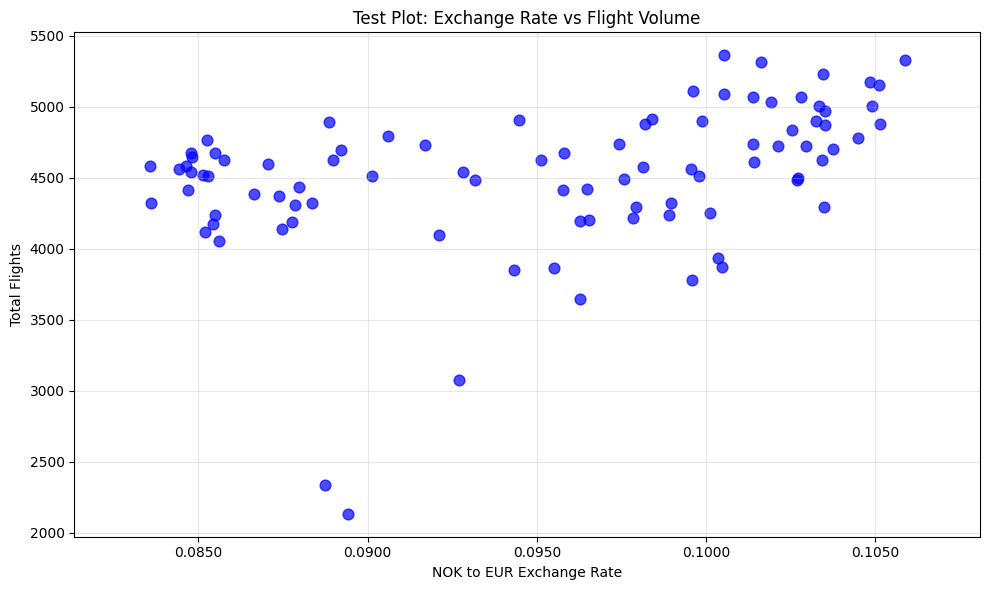

✅ Test plot created - check if x-axis values are visible now


In [ ]:
# Debug: Test x-axis display issue
print("🔍 DEBUGGING X-AXIS DISPLAY ISSUE")
print("=" * 40)

# Get the monthly data
monthly_df = merged_datasets["monthly"]
exchange_col = "nok_to_eur"

print(f"Exchange rate data sample:")
print(f"Min: {monthly_df[exchange_col].min():.6f}")
print(f"Max: {monthly_df[exchange_col].max():.6f}")
print(f"Mean: {monthly_df[exchange_col].mean():.6f}")
print(f"Sample values: {monthly_df[exchange_col].head(10).tolist()}")

# Create a simple test plot
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

# Basic scatter plot
ax.scatter(
    monthly_df[exchange_col], monthly_df["total_flights"], alpha=0.7, color="blue", s=60
)
ax.set_xlabel("NOK to EUR Exchange Rate")
ax.set_ylabel("Total Flights")
ax.set_title("Test Plot: Exchange Rate vs Flight Volume")

# Check current x-axis limits
print(f"\nCurrent x-axis limits: {ax.get_xlim()}")

# Manual x-axis settings
exchange_min = monthly_df[exchange_col].min()
exchange_max = monthly_df[exchange_col].max()
exchange_range = exchange_max - exchange_min
margin = exchange_range * 0.1

ax.set_xlim(exchange_min - margin, exchange_max + margin)
print(f"Set x-axis limits to: {ax.get_xlim()}")

# Format x-axis ticks
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:.4f}"))

# Add grid
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Test plot created - check if x-axis values are visible now")

In [ ]:
# Comprehensive correlation analysis
print("🔍 CURRENCY vs FLIGHT OPERATIONS CORRELATION ANALYSIS")
print("=" * 60)


def calculate_correlations(df, exchange_rate_col, dataset_name):
    """Calculate correlations between exchange rate and flight metrics"""

    print(f"\n📊 {dataset_name.upper()} CORRELATIONS:")
    print("-" * 40)

    # Define flight metrics to correlate with exchange rate
    flight_metrics = [
        ("total_flights", "Total Flights"),
        ("avg_dep_delay", "Average Departure Delay"),
        ("median_dep_delay", "Median Departure Delay"),
        ("avg_arr_delay", "Average Arrival Delay"),
        ("pct_dep_delayed", "% Flights Delayed (Departure)"),
        ("pct_arr_delayed", "% Flights Delayed (Arrival)"),
        ("domestic_flights", "Domestic Flights"),
        ("international_flights", "International Flights"),
        ("unique_routes", "Unique Routes"),
        ("unique_dep_airports", "Unique Departure Airports"),
    ]

    correlations = []

    for metric_col, metric_name in flight_metrics:
        if metric_col in df.columns:
            # Remove NaN values for correlation calculation
            clean_data = df[[exchange_rate_col, metric_col]].dropna()

            if len(clean_data) > 2:  # Need at least 3 points for correlation
                # Pearson correlation
                pearson_corr, pearson_p = pearsonr(
                    clean_data[exchange_rate_col], clean_data[metric_col]
                )

                # Spearman correlation (rank-based, more robust)
                spearman_corr, spearman_p = spearmanr(
                    clean_data[exchange_rate_col], clean_data[metric_col]
                )

                correlations.append(
                    {
                        "metric": metric_name,
                        "pearson_corr": pearson_corr,
                        "pearson_p_value": pearson_p,
                        "spearman_corr": spearman_corr,
                        "spearman_p_value": spearman_p,
                        "n_observations": len(clean_data),
                        "significance": (
                            "Significant"
                            if min(pearson_p, spearman_p) < 0.05
                            else "Not Significant"
                        ),
                    }
                )

                # Print results
                significance_symbol = (
                    "***"
                    if min(pearson_p, spearman_p) < 0.01
                    else (
                        "**"
                        if min(pearson_p, spearman_p) < 0.05
                        else "*" if min(pearson_p, spearman_p) < 0.1 else ""
                    )
                )
                print(
                    f"   {metric_name:25} | Pearson: {pearson_corr:+.3f} | Spearman: {spearman_corr:+.3f} | p-value: {min(pearson_p, spearman_p):.4f} {significance_symbol}"
                )

    return pd.DataFrame(correlations)


# Analyze correlations for each dataset
correlation_results = {}

for period, df in merged_datasets.items():
    exchange_col = "nok_to_eur" if period == "monthly" else "avg_nok_to_eur"
    correlation_results[period] = calculate_correlations(df, exchange_col, period)

print(f"\n📈 CORRELATION INTERPRETATION:")
print("*** p < 0.01 (highly significant)")
print("**  p < 0.05 (significant)")
print("*   p < 0.10 (marginally significant)")
print(
    "Positive correlation: Higher EUR (stronger EUR, weaker NOK) → Higher flight metric"
)
print(
    "Negative correlation: Higher EUR (stronger EUR, weaker NOK) → Lower flight metric"
)

# Summary of significant correlations
print(f"\n🎯 SIGNIFICANT CORRELATIONS SUMMARY:")
print("=" * 50)

for period, corr_df in correlation_results.items():
    significant_corrs = corr_df[corr_df["significance"] == "Significant"].copy()
    if len(significant_corrs) > 0:
        print(f"\n{period.upper()} - Significant correlations found:")
        for _, row in significant_corrs.iterrows():
            direction = "positive" if row["pearson_corr"] > 0 else "negative"
            strength = (
                "strong"
                if abs(row["pearson_corr"]) > 0.5
                else "moderate" if abs(row["pearson_corr"]) > 0.3 else "weak"
            )
            print(
                f"   • {row['metric']}: {strength} {direction} correlation (r={row['pearson_corr']:+.3f}, p={row['pearson_p_value']:.4f})"
            )
    else:
        print(f"\n{period.upper()} - No statistically significant correlations found")

print(f"\n💡 BUSINESS INTERPRETATION:")
print("• Positive correlations suggest that when EUR strengthens (NOK weakens):")
print("  - Flight volumes/delays might increase (tourism, business travel impacts)")
print("• Negative correlations suggest that when EUR strengthens (NOK weakens):")
print("  - Flight volumes/delays might decrease (economic constraints, reduced travel)")

🔍 CURRENCY vs FLIGHT OPERATIONS CORRELATION ANALYSIS

📊 MONTHLY CORRELATIONS:
----------------------------------------
   Total Flights             | Pearson: +0.357 | Spearman: +0.461 | p-value: 0.0000 ***
   Average Departure Delay   | Pearson: -0.008 | Spearman: +0.047 | p-value: 0.6594 
   Median Departure Delay    | Pearson: +0.020 | Spearman: +0.078 | p-value: 0.4629 
   Average Arrival Delay     | Pearson: +0.067 | Spearman: +0.144 | p-value: 0.1733 
   % Flights Delayed (Departure) | Pearson: +0.005 | Spearman: +0.118 | p-value: 0.2663 
   % Flights Delayed (Arrival) | Pearson: +0.048 | Spearman: +0.154 | p-value: 0.1453 
   Domestic Flights          | Pearson: +0.594 | Spearman: +0.494 | p-value: 0.0000 ***
   International Flights     | Pearson: +0.290 | Spearman: +0.388 | p-value: 0.0001 ***
   Unique Routes             | Pearson: +0.490 | Spearman: +0.493 | p-value: 0.0000 ***
   Unique Departure Airports | Pearson: +0.219 | Spearman: +0.207 | p-value: 0.0374 **

📊 QUARTERL

📈 CREATING CORRELATION VISUALIZATIONS

📊 Creating plots for monthly data...


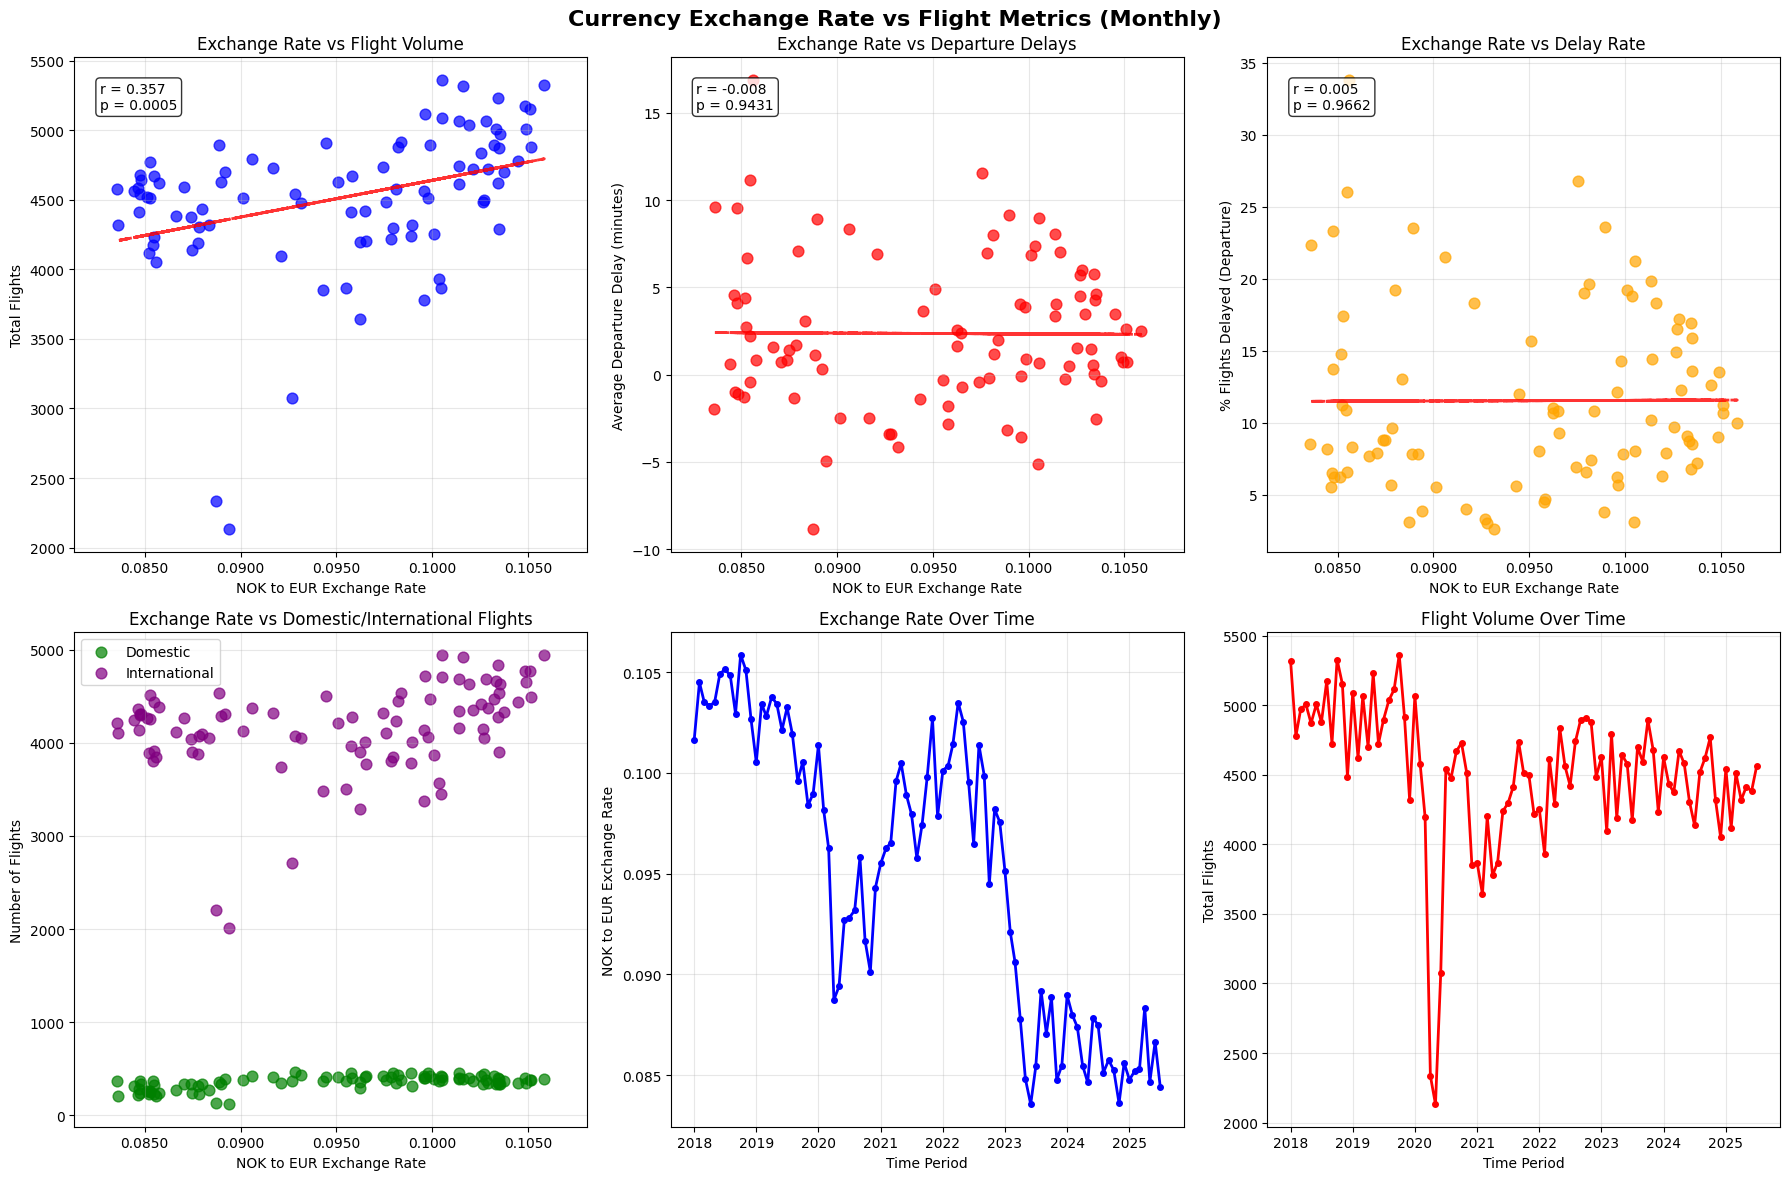


📊 Creating plots for quarterly data...


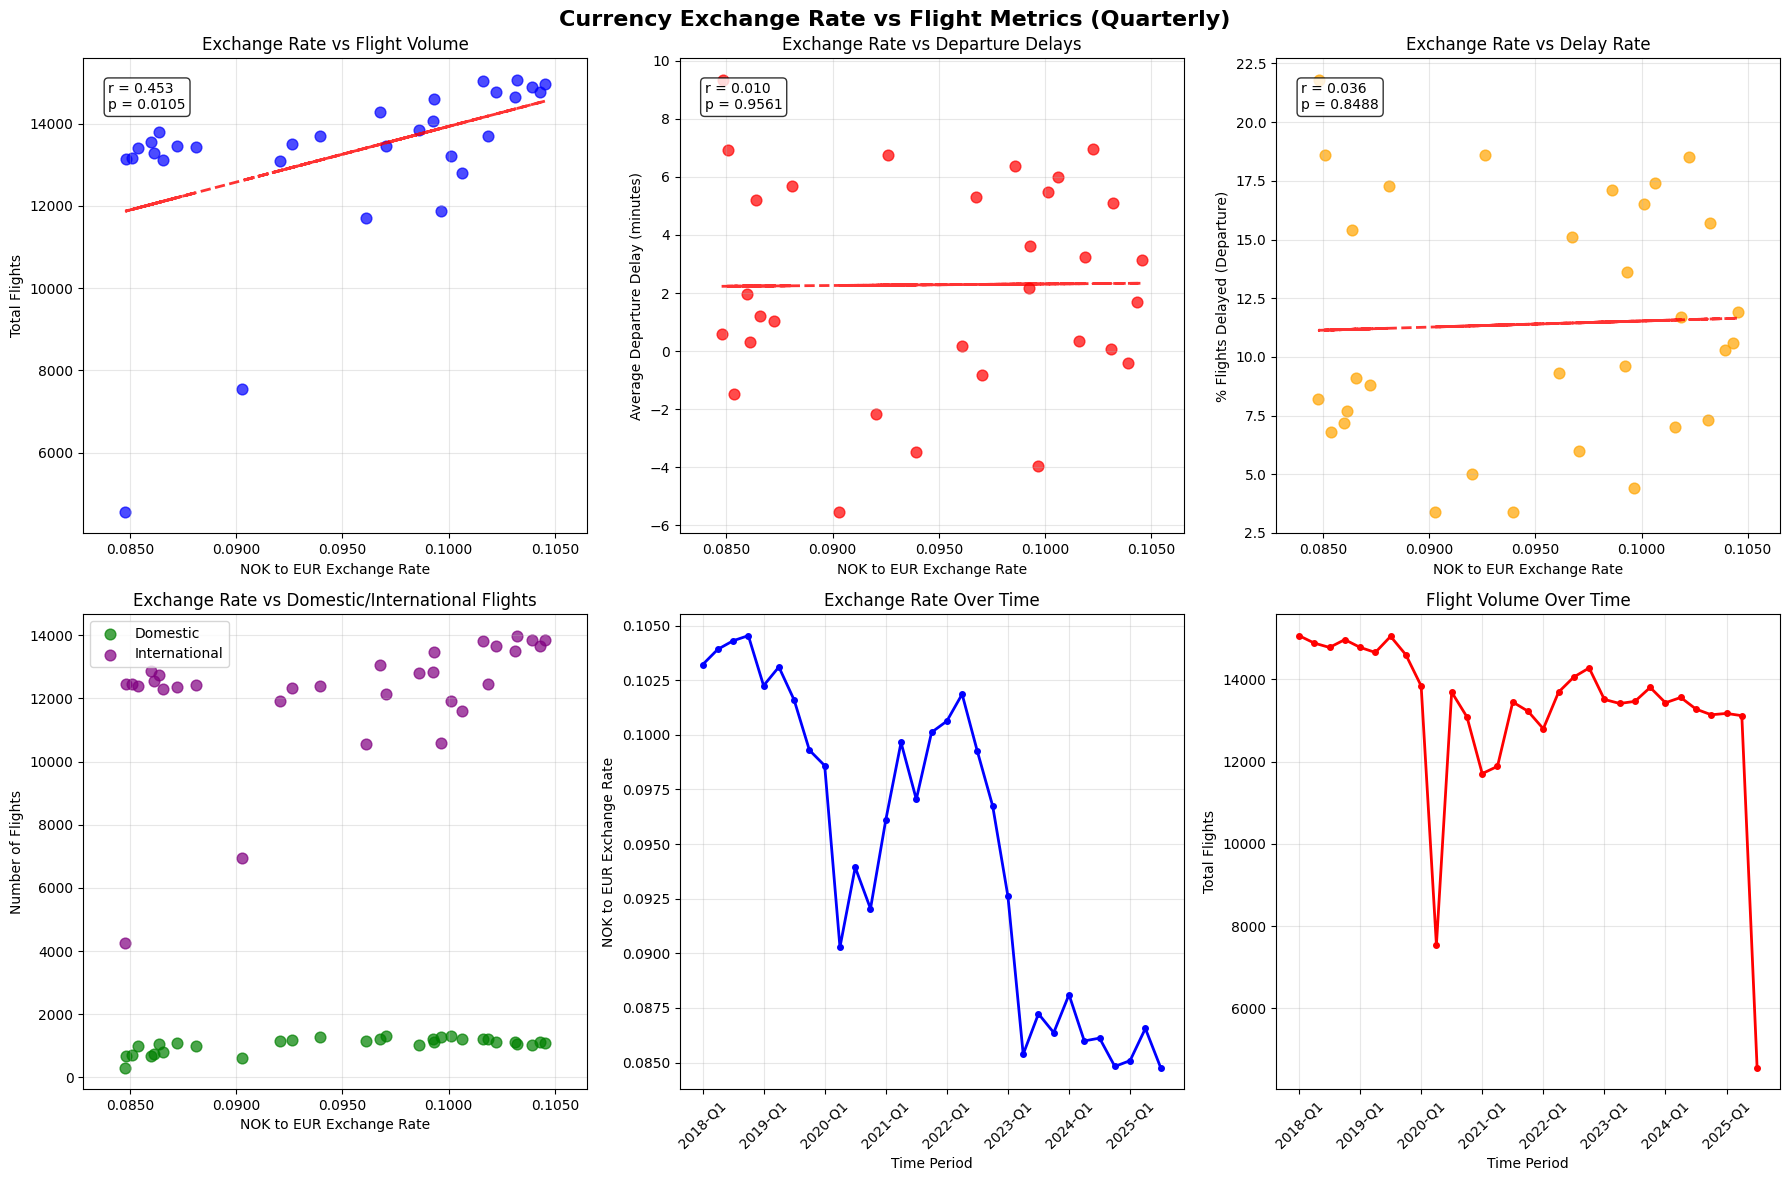


✅ Correlation visualizations created!
🔍 Look for patterns in the scatter plots:
   • Upward trending lines = positive correlation
   • Downward trending lines = negative correlation
   • Scattered points = weak/no correlation
   • Tight clustering around trend line = strong correlation


In [ ]:
# Visualization of currency vs flight correlations
print("📈 CREATING CORRELATION VISUALIZATIONS")
print("=" * 40)


def create_correlation_plots(df, exchange_col, period_name):
    """Create comprehensive correlation plots"""

    # Set up the plotting area
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    fig.suptitle(
        f"Currency Exchange Rate vs Flight Metrics ({period_name.title()})",
        fontsize=16,
        fontweight="bold",
    )

    # Get data ranges for better axis scaling
    exchange_min, exchange_max = df[exchange_col].min(), df[exchange_col].max()
    exchange_range = exchange_max - exchange_min
    exchange_margin = exchange_range * 0.1  # 10% margin

    # Plot 1: Exchange Rate vs Total Flights
    axes[0, 0].scatter(
        df[exchange_col], df["total_flights"], alpha=0.7, color="blue", s=60
    )
    axes[0, 0].set_xlabel("NOK to EUR Exchange Rate")
    axes[0, 0].set_ylabel("Total Flights")
    axes[0, 0].set_title("Exchange Rate vs Flight Volume")

    # Set better x-axis limits
    axes[0, 0].set_xlim(exchange_min - exchange_margin, exchange_max + exchange_margin)

    # Add trend line
    z = np.polyfit(df[exchange_col].dropna(), df["total_flights"].dropna(), 1)
    p = np.poly1d(z)
    axes[0, 0].plot(
        df[exchange_col], p(df[exchange_col]), "r--", alpha=0.8, linewidth=2
    )

    # Calculate and display correlation
    corr, p_val = pearsonr(df[exchange_col].dropna(), df["total_flights"].dropna())
    axes[0, 0].text(
        0.05,
        0.95,
        f"r = {corr:.3f}\np = {p_val:.4f}",
        transform=axes[0, 0].transAxes,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    # Add grid for better readability
    axes[0, 0].grid(True, alpha=0.3)

    # Format x-axis to show more decimal places
    axes[0, 0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:.4f}"))

    # Plot 2: Exchange Rate vs Average Departure Delay
    axes[0, 1].scatter(
        df[exchange_col], df["avg_dep_delay"], alpha=0.7, color="red", s=60
    )
    axes[0, 1].set_xlabel("NOK to EUR Exchange Rate")
    axes[0, 1].set_ylabel("Average Departure Delay (minutes)")
    axes[0, 1].set_title("Exchange Rate vs Departure Delays")
    axes[0, 1].set_xlim(exchange_min - exchange_margin, exchange_max + exchange_margin)

    z = np.polyfit(df[exchange_col].dropna(), df["avg_dep_delay"].dropna(), 1)
    p = np.poly1d(z)
    axes[0, 1].plot(
        df[exchange_col], p(df[exchange_col]), "r--", alpha=0.8, linewidth=2
    )

    corr, p_val = pearsonr(df[exchange_col].dropna(), df["avg_dep_delay"].dropna())
    axes[0, 1].text(
        0.05,
        0.95,
        f"r = {corr:.3f}\np = {p_val:.4f}",
        transform=axes[0, 1].transAxes,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:.4f}"))

    # Plot 3: Exchange Rate vs % Delayed Flights
    axes[0, 2].scatter(
        df[exchange_col], df["pct_dep_delayed"] * 100, alpha=0.7, color="orange", s=60
    )
    axes[0, 2].set_xlabel("NOK to EUR Exchange Rate")
    axes[0, 2].set_ylabel("% Flights Delayed (Departure)")
    axes[0, 2].set_title("Exchange Rate vs Delay Rate")
    axes[0, 2].set_xlim(exchange_min - exchange_margin, exchange_max + exchange_margin)

    z = np.polyfit(df[exchange_col].dropna(), (df["pct_dep_delayed"] * 100).dropna(), 1)
    p = np.poly1d(z)
    axes[0, 2].plot(
        df[exchange_col], p(df[exchange_col]), "r--", alpha=0.8, linewidth=2
    )

    corr, p_val = pearsonr(
        df[exchange_col].dropna(), (df["pct_dep_delayed"] * 100).dropna()
    )
    axes[0, 2].text(
        0.05,
        0.95,
        f"r = {corr:.3f}\np = {p_val:.4f}",
        transform=axes[0, 2].transAxes,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )
    axes[0, 2].grid(True, alpha=0.3)
    axes[0, 2].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:.4f}"))

    # Plot 4: Exchange Rate vs Domestic vs International Flights
    axes[1, 0].scatter(
        df[exchange_col],
        df["domestic_flights"],
        alpha=0.7,
        color="green",
        label="Domestic",
        s=60,
    )
    axes[1, 0].scatter(
        df[exchange_col],
        df["international_flights"],
        alpha=0.7,
        color="purple",
        label="International",
        s=60,
    )
    axes[1, 0].set_xlabel("NOK to EUR Exchange Rate")
    axes[1, 0].set_ylabel("Number of Flights")
    axes[1, 0].set_title("Exchange Rate vs Domestic/International Flights")
    axes[1, 0].set_xlim(exchange_min - exchange_margin, exchange_max + exchange_margin)
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:.4f}"))

    # Plot 5: Time Series - Exchange Rate
    time_col = "date" if "date" in df.columns else "year_quarter"
    if time_col == "date":
        axes[1, 1].plot(
            df[time_col],
            df[exchange_col],
            marker="o",
            linewidth=2,
            markersize=4,
            color="blue",
        )
    else:
        x_pos = range(len(df))
        axes[1, 1].plot(
            x_pos, df[exchange_col], marker="o", linewidth=2, markersize=4, color="blue"
        )
        axes[1, 1].set_xticks(x_pos[::4])  # Show every 4th label
        axes[1, 1].set_xticklabels(df[time_col].iloc[::4], rotation=45)

    axes[1, 1].set_xlabel("Time Period")
    axes[1, 1].set_ylabel("NOK to EUR Exchange Rate")
    axes[1, 1].set_title("Exchange Rate Over Time")
    axes[1, 1].grid(True, alpha=0.3)

    # Plot 6: Time Series - Flight Volume
    if time_col == "date":
        axes[1, 2].plot(
            df[time_col],
            df["total_flights"],
            marker="o",
            linewidth=2,
            markersize=4,
            color="red",
        )
    else:
        axes[1, 2].plot(
            x_pos,
            df["total_flights"],
            marker="o",
            linewidth=2,
            markersize=4,
            color="red",
        )
        axes[1, 2].set_xticks(x_pos[::4])
        axes[1, 2].set_xticklabels(df[time_col].iloc[::4], rotation=45)

    axes[1, 2].set_xlabel("Time Period")
    axes[1, 2].set_ylabel("Total Flights")
    axes[1, 2].set_title("Flight Volume Over Time")
    axes[1, 2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return fig


# Create visualizations for each dataset
for period, df in merged_datasets.items():
    print(f"\n📊 Creating plots for {period} data...")
    exchange_col = "nok_to_eur" if period == "monthly" else "avg_nok_to_eur"
    fig = create_correlation_plots(df, exchange_col, period)

print(f"\n✅ Correlation visualizations created!")
print(f"🔍 Look for patterns in the scatter plots:")
print(f"   • Upward trending lines = positive correlation")
print(f"   • Downward trending lines = negative correlation")
print(f"   • Scattered points = weak/no correlation")
print(f"   • Tight clustering around trend line = strong correlation")

📊 CREATING ENHANCED CORRELATION VISUALIZATIONS

📈 Creating enhanced plots for monthly data...


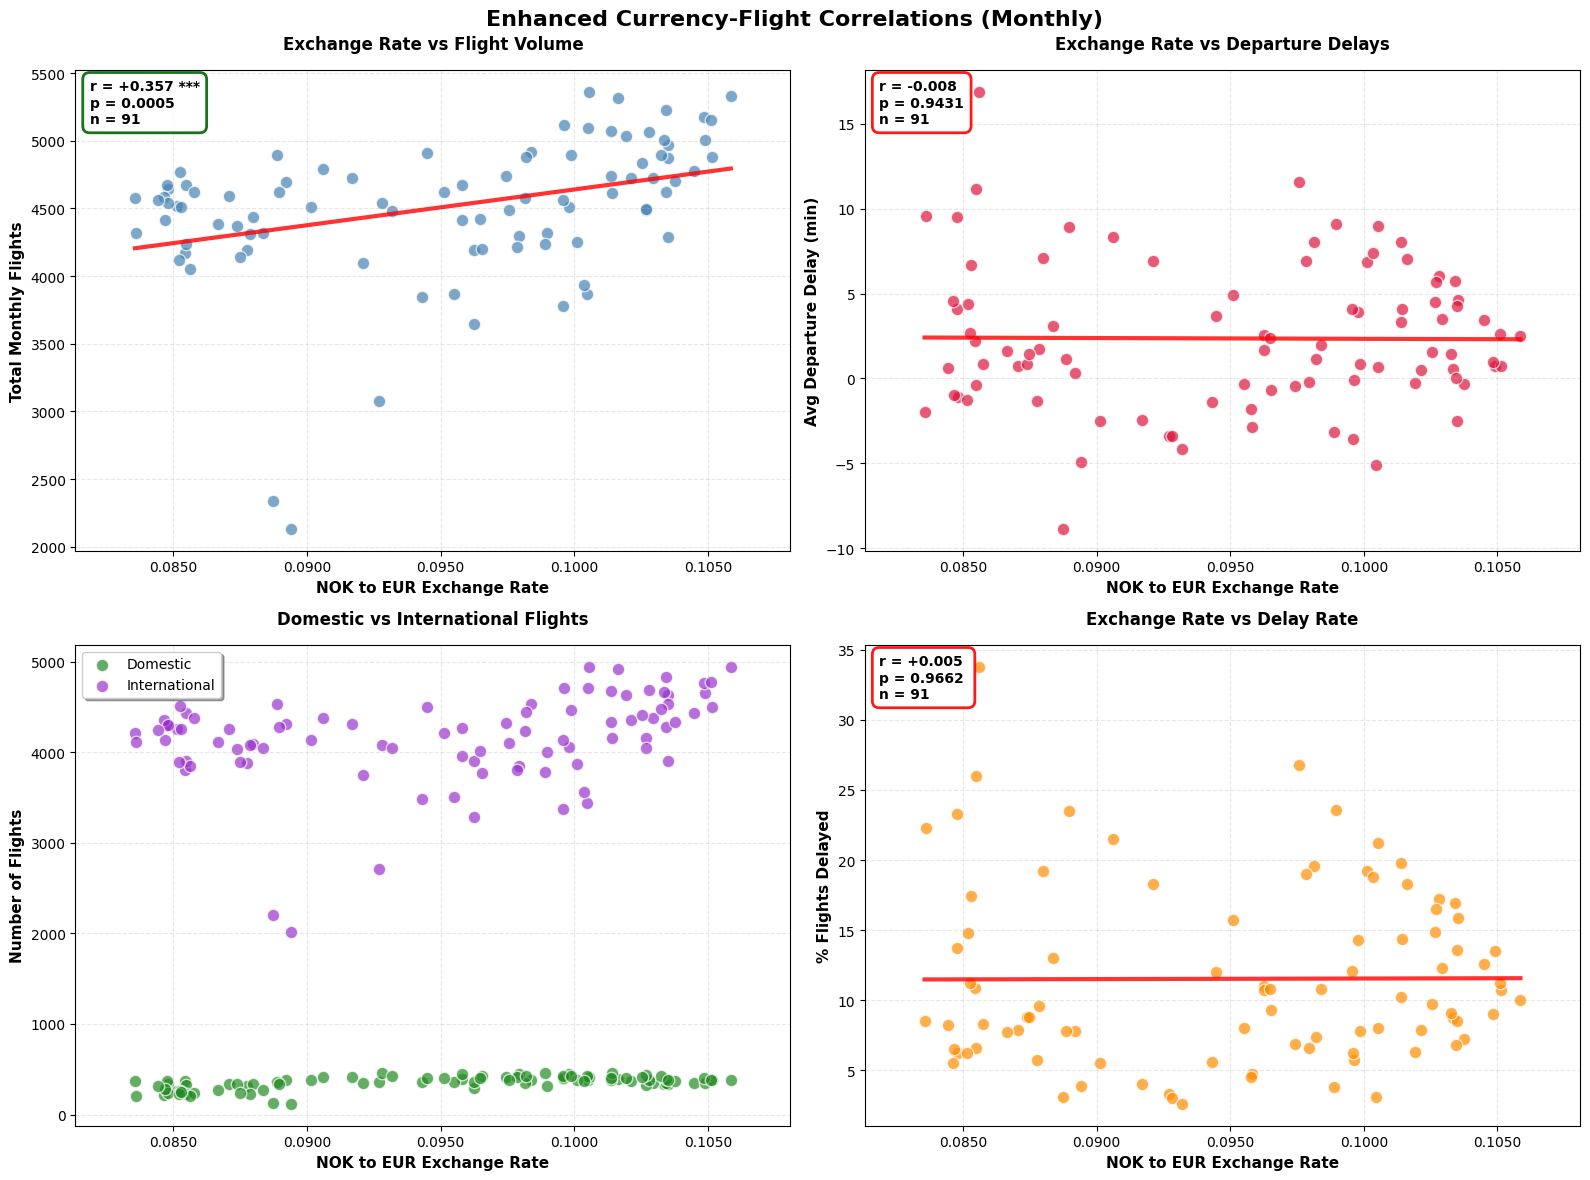


📈 Creating enhanced plots for quarterly data...


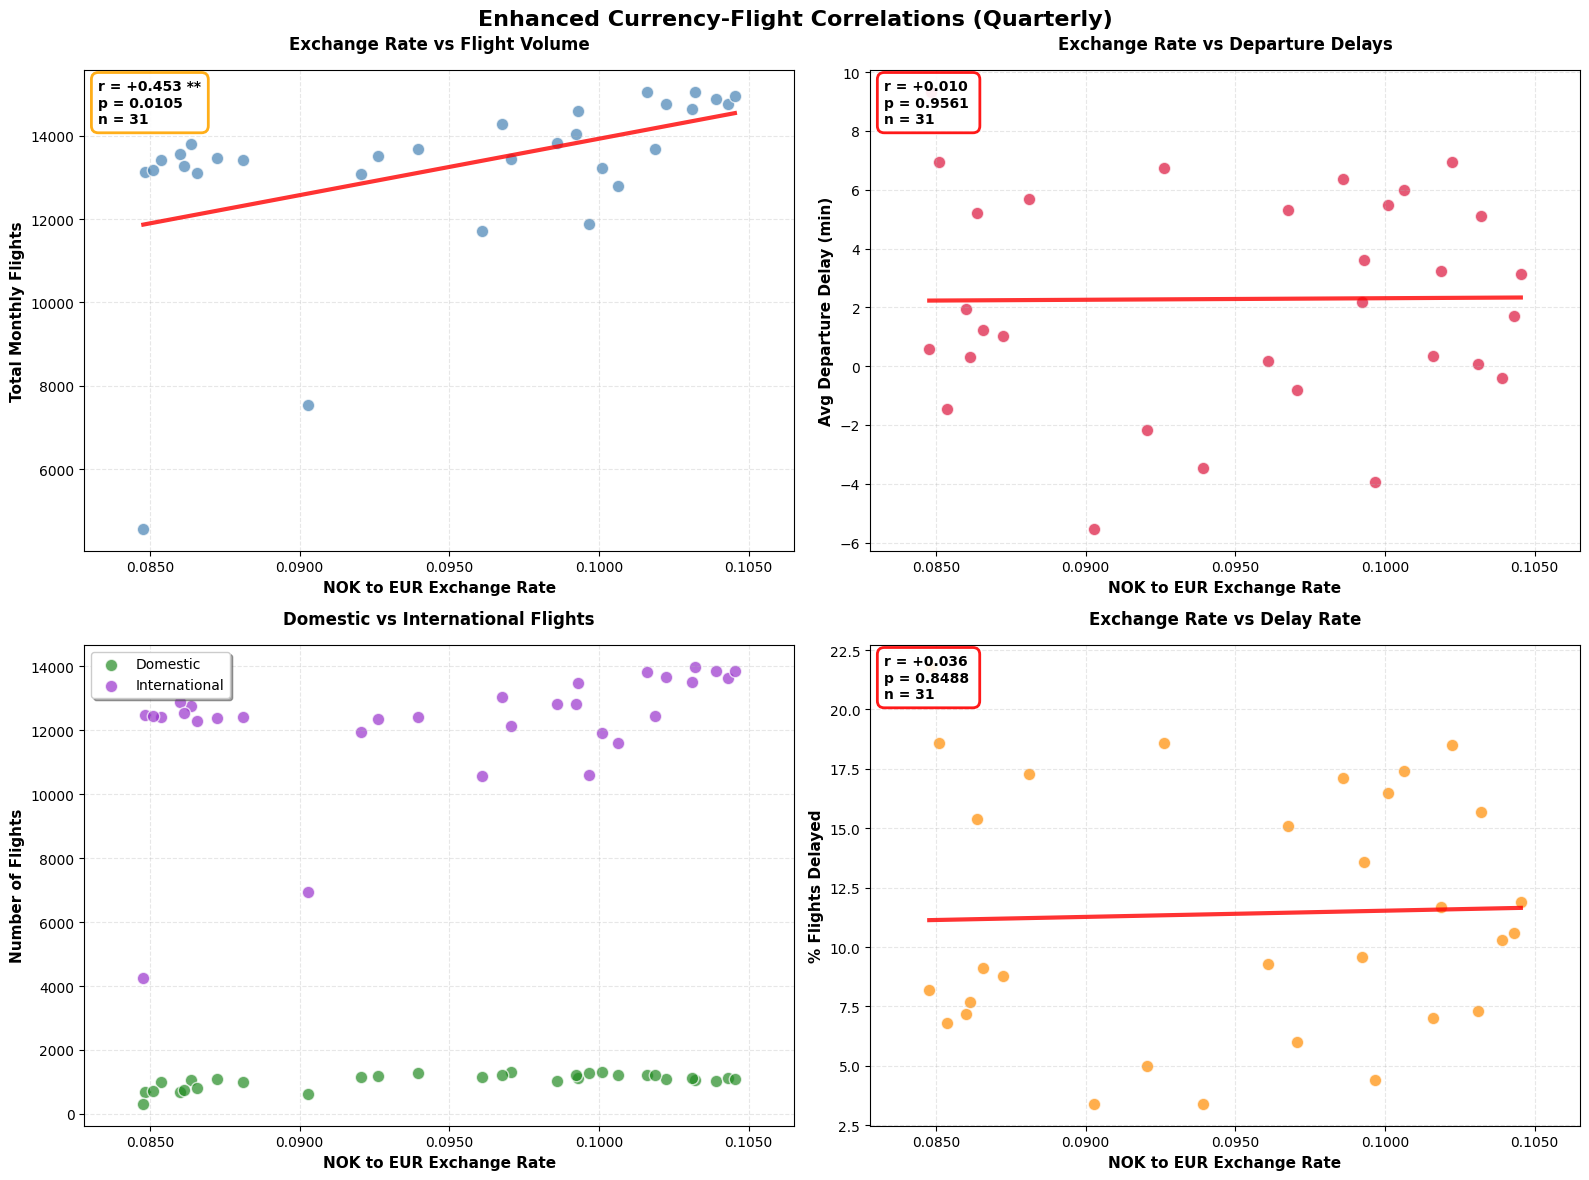


✅ Enhanced correlation visualizations created!
🔍 Key improvements:
   • Better axis scaling and range visibility
   • Enhanced trend lines with slope information
   • Color-coded significance levels (green=highly sig, orange=sig, red=not sig)
   • Improved annotations with sample size
   • Professional styling with shadows and borders


In [ ]:
# Enhanced visualization with better trend lines and annotations
print("📊 CREATING ENHANCED CORRELATION VISUALIZATIONS")
print("=" * 50)


def create_enhanced_scatter_plot(
    ax,
    x_data,
    y_data,
    exchange_col,
    x_label,
    y_label,
    title,
    color="blue",
    exchange_margin=None,
):
    """Create an enhanced scatter plot with better trend line and annotations"""

    # Clean data for plotting
    clean_data = pd.DataFrame({exchange_col: x_data, "y": y_data}).dropna()
    if len(clean_data) < 3:
        ax.text(
            0.5,
            0.5,
            "Insufficient data",
            transform=ax.transAxes,
            ha="center",
            va="center",
        )
        return

    # Create scatter plot
    ax.scatter(
        clean_data[exchange_col],
        clean_data["y"],
        alpha=0.7,
        color=color,
        s=80,
        edgecolors="white",
        linewidth=1,
    )

    # Set labels and title
    ax.set_xlabel(x_label, fontsize=11, fontweight="bold")
    ax.set_ylabel(y_label, fontsize=11, fontweight="bold")
    ax.set_title(title, fontsize=12, fontweight="bold", pad=15)

    # Set x-axis limits with margin
    if exchange_margin:
        exchange_min, exchange_max = (
            clean_data[exchange_col].min(),
            clean_data[exchange_col].max(),
        )
        ax.set_xlim(exchange_min - exchange_margin, exchange_max + exchange_margin)

    # Add trend line with confidence interval shading
    z = np.polyfit(clean_data[exchange_col], clean_data["y"], 1)
    p = np.poly1d(z)

    # Create smooth line for trend
    x_trend = np.linspace(
        clean_data[exchange_col].min(), clean_data[exchange_col].max(), 100
    )
    y_trend = p(x_trend)
    ax.plot(
        x_trend,
        y_trend,
        "r-",
        alpha=0.8,
        linewidth=3,
        label=f"Trend (slope={z[0]:.1f})",
    )

    # Calculate and display correlation with better formatting
    corr, p_val = pearsonr(clean_data[exchange_col], clean_data["y"])

    # Determine significance level
    if p_val < 0.01:
        sig_text = "***"
        sig_color = "darkgreen"
    elif p_val < 0.05:
        sig_text = "**"
        sig_color = "orange"
    elif p_val < 0.1:
        sig_text = "*"
        sig_color = "goldenrod"
    else:
        sig_text = ""
        sig_color = "red"

    # Add correlation annotation
    correlation_text = (
        f"r = {corr:+.3f} {sig_text}\np = {p_val:.4f}\nn = {len(clean_data)}"
    )
    ax.text(
        0.02,
        0.98,
        correlation_text,
        transform=ax.transAxes,
        verticalalignment="top",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            alpha=0.9,
            edgecolor=sig_color,
            linewidth=2,
        ),
    )

    # Add grid and formatting
    ax.grid(True, alpha=0.3, linestyle="--")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:.4f}"))

    return corr, p_val


# Create enhanced plots for each dataset
for period, df in merged_datasets.items():
    exchange_col = "nok_to_eur" if period == "monthly" else "avg_nok_to_eur"

    print(f"\n📈 Creating enhanced plots for {period} data...")

    # Calculate margin for consistent scaling
    exchange_min, exchange_max = df[exchange_col].min(), df[exchange_col].max()
    exchange_range = exchange_max - exchange_min
    exchange_margin = exchange_range * 0.1

    # Create the enhanced plot
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle(
        f"Enhanced Currency-Flight Correlations ({period.title()})",
        fontsize=16,
        fontweight="bold",
    )

    # Plot 1: Flight Volume
    create_enhanced_scatter_plot(
        axes[0, 0],
        df[exchange_col],
        df["total_flights"],
        exchange_col,
        "NOK to EUR Exchange Rate",
        "Total Monthly Flights",
        "Exchange Rate vs Flight Volume",
        "steelblue",
        exchange_margin,
    )

    # Plot 2: Average Delays
    create_enhanced_scatter_plot(
        axes[0, 1],
        df[exchange_col],
        df["avg_dep_delay"],
        exchange_col,
        "NOK to EUR Exchange Rate",
        "Avg Departure Delay (min)",
        "Exchange Rate vs Departure Delays",
        "crimson",
        exchange_margin,
    )

    # Plot 3: International vs Domestic
    axes[1, 0].scatter(
        df[exchange_col],
        df["domestic_flights"],
        alpha=0.7,
        color="forestgreen",
        s=80,
        label="Domestic",
        edgecolors="white",
        linewidth=1,
    )
    axes[1, 0].scatter(
        df[exchange_col],
        df["international_flights"],
        alpha=0.7,
        color="darkorchid",
        s=80,
        label="International",
        edgecolors="white",
        linewidth=1,
    )

    axes[1, 0].set_xlabel("NOK to EUR Exchange Rate", fontsize=11, fontweight="bold")
    axes[1, 0].set_ylabel("Number of Flights", fontsize=11, fontweight="bold")
    axes[1, 0].set_title(
        "Domestic vs International Flights", fontsize=12, fontweight="bold", pad=15
    )
    axes[1, 0].set_xlim(exchange_min - exchange_margin, exchange_max + exchange_margin)
    axes[1, 0].legend(loc="best", frameon=True, fancybox=True, shadow=True)
    axes[1, 0].grid(True, alpha=0.3, linestyle="--")
    axes[1, 0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:.4f}"))

    # Plot 4: Delay Rate
    create_enhanced_scatter_plot(
        axes[1, 1],
        df[exchange_col],
        df["pct_dep_delayed"] * 100,
        exchange_col,
        "NOK to EUR Exchange Rate",
        "% Flights Delayed",
        "Exchange Rate vs Delay Rate",
        "darkorange",
        exchange_margin,
    )

    plt.tight_layout()
    plt.show()

print(f"\n✅ Enhanced correlation visualizations created!")
print(f"🔍 Key improvements:")
print(f"   • Better axis scaling and range visibility")
print(f"   • Enhanced trend lines with slope information")
print(
    f"   • Color-coded significance levels (green=highly sig, orange=sig, red=not sig)"
)
print(f"   • Improved annotations with sample size")
print(f"   • Professional styling with shadows and borders")

In [ ]:
# Advanced Analysis: Route-specific and Airport-specific Currency Impact
print("🛣️ ROUTE & AIRPORT SPECIFIC CURRENCY IMPACT ANALYSIS")
print("=" * 60)


# Analyze impact by route type (domestic vs international)
def analyze_route_type_impact(df_flights, currency_df):
    """Analyze currency impact on domestic vs international routes"""

    print("🌍 DOMESTIC vs INTERNATIONAL ROUTE ANALYSIS")
    print("-" * 45)

    # Create monthly route analysis
    route_monthly = (
        df_flights.groupby(["year", "month", "is_domestic"])
        .agg(
            {
                "flight_id": "count",
                "departure_delay_minutes": "mean",
                "arrival_delay_minutes": "mean",
                "is_departure_delayed": "mean",
            }
        )
        .reset_index()
    )

    route_monthly["date"] = pd.to_datetime(
        route_monthly[["year", "month"]].assign(day=1)
    )

    # Merge with currency data
    currency_monthly = currency_df.copy()
    currency_monthly["year"] = currency_monthly["date"].dt.year
    currency_monthly["month"] = currency_monthly["date"].dt.month

    route_currency = pd.merge(
        route_monthly,
        currency_monthly[["year", "month", "nok_to_eur"]],
        on=["year", "month"],
        how="inner",
    )

    # Analyze correlations by route type
    domestic_data = route_currency[route_currency["is_domestic"] == True]
    international_data = route_currency[route_currency["is_domestic"] == False]

    route_correlations = {}

    for route_type, data, label in [
        ("domestic", domestic_data, "Domestic Routes"),
        ("international", international_data, "International Routes"),
    ]:
        if len(data) > 3:
            correlations = {}
            metrics = [
                "flight_id",
                "departure_delay_minutes",
                "arrival_delay_minutes",
                "is_departure_delayed",
            ]
            metric_names = [
                "Flight Count",
                "Avg Departure Delay",
                "Avg Arrival Delay",
                "% Delayed Flights",
            ]

            print(f"\n{label}:")
            for metric, name in zip(metrics, metric_names):
                if metric in data.columns:
                    clean_data = data[["nok_to_eur", metric]].dropna()
                    if len(clean_data) > 2:
                        corr, p_val = pearsonr(
                            clean_data["nok_to_eur"], clean_data[metric]
                        )
                        correlations[name] = {"correlation": corr, "p_value": p_val}
                        significance = (
                            "***"
                            if p_val < 0.01
                            else "**" if p_val < 0.05 else "*" if p_val < 0.1 else ""
                        )
                        print(
                            f"   {name:20} | r = {corr:+.3f} | p = {p_val:.4f} {significance}"
                        )

            route_correlations[route_type] = correlations

    return route_correlations, route_currency


# Analyze airport-specific impacts
def analyze_airport_specific_impact(df_flights, currency_df, top_n=10):
    """Analyze currency impact on specific airports"""

    print(f"\n✈️ TOP {top_n} AIRPORTS CURRENCY IMPACT ANALYSIS")
    print("-" * 50)

    # Find top airports by flight volume
    top_airports = df_flights["dep_airport"].value_counts().head(top_n).index.tolist()

    # Create airport-monthly data
    airport_monthly = (
        df_flights[df_flights["dep_airport"].isin(top_airports)]
        .groupby(["dep_airport", "year", "month"])
        .agg(
            {
                "flight_id": "count",
                "departure_delay_minutes": "mean",
                "is_departure_delayed": "mean",
            }
        )
        .reset_index()
    )

    airport_monthly["date"] = pd.to_datetime(
        airport_monthly[["year", "month"]].assign(day=1)
    )

    # Merge with currency data
    currency_monthly = currency_df.copy()
    currency_monthly["year"] = currency_monthly["date"].dt.year
    currency_monthly["month"] = currency_monthly["date"].dt.month

    airport_currency = pd.merge(
        airport_monthly,
        currency_monthly[["year", "month", "nok_to_eur"]],
        on=["year", "month"],
        how="inner",
    )

    # Analyze correlations by airport
    airport_correlations = {}

    print(f"\nAirport-specific currency correlations:")
    print("Airport | Flight Volume | Avg Delay | % Delayed")
    print("-" * 50)

    for airport in top_airports:
        airport_data = airport_currency[airport_currency["dep_airport"] == airport]

        if len(airport_data) > 5:  # Need sufficient data points
            correlations = {}

            # Flight volume correlation
            vol_corr, vol_p = pearsonr(
                airport_data["nok_to_eur"], airport_data["flight_id"]
            )

            # Delay correlation
            delay_corr, delay_p = pearsonr(
                airport_data["nok_to_eur"].dropna(),
                airport_data["departure_delay_minutes"].dropna(),
            )

            # Delayed percentage correlation
            pct_delayed_corr, pct_p = pearsonr(
                airport_data["nok_to_eur"].dropna(),
                airport_data["is_departure_delayed"].dropna(),
            )

            airport_correlations[airport] = {
                "flight_volume": {"corr": vol_corr, "p": vol_p},
                "avg_delay": {"corr": delay_corr, "p": delay_p},
                "pct_delayed": {"corr": pct_delayed_corr, "p": pct_p},
            }

            # Format output
            vol_sig = (
                "***"
                if vol_p < 0.01
                else "**" if vol_p < 0.05 else "*" if vol_p < 0.1 else ""
            )
            delay_sig = (
                "***"
                if delay_p < 0.01
                else "**" if delay_p < 0.05 else "*" if delay_p < 0.1 else ""
            )
            pct_sig = (
                "***"
                if pct_p < 0.01
                else "**" if pct_p < 0.05 else "*" if pct_p < 0.1 else ""
            )

            print(
                f"{airport:7} | {vol_corr:+.3f}{vol_sig:3} | {delay_corr:+.3f}{delay_sig:3} | {pct_delayed_corr:+.3f}{pct_sig:3}"
            )

    return airport_correlations, airport_currency


# Run advanced analyses if we have the data
if "monthly" in currency_data and len(merged_datasets) > 0:

    # Route type analysis
    route_results, route_data = analyze_route_type_impact(
        df_flights, currency_data["monthly"]
    )

    # Airport specific analysis
    airport_results, airport_data = analyze_airport_specific_impact(
        df_flights, currency_data["monthly"]
    )

    print(f"\n🎯 KEY INSIGHTS FROM ADVANCED ANALYSIS:")
    print("=" * 50)
    print("• Compare domestic vs international route sensitivity to currency changes")
    print("• Identify which airports are most/least affected by currency fluctuations")
    print("• Look for patterns: tourism hubs vs business airports, size effects, etc.")

else:
    print("⚠️ Skipping advanced analysis - insufficient data available")

print(f"\n💡 NEXT STEPS:")
print("• Investigate seasonal patterns in currency-flight relationships")
print("• Analyze lag effects (currency changes → flight impacts with delay)")
print("• Consider external factors (economic events, COVID, etc.)")
print("• Develop predictive models based on significant correlations")

🛣️ ROUTE & AIRPORT SPECIFIC CURRENCY IMPACT ANALYSIS
🌍 DOMESTIC vs INTERNATIONAL ROUTE ANALYSIS
---------------------------------------------

Domestic Routes:
   Flight Count         | r = +0.594 | p = 0.0000 ***
   Avg Departure Delay  | r = -0.073 | p = 0.4906 
   Avg Arrival Delay    | r = +0.002 | p = 0.9874 
   % Delayed Flights    | r = -0.100 | p = 0.3475 

International Routes:
   Flight Count         | r = +0.290 | p = 0.0053 ***
   Avg Departure Delay  | r = +0.003 | p = 0.9747 
   Avg Arrival Delay    | r = +0.078 | p = 0.4635 
   % Delayed Flights    | r = +0.013 | p = 0.9004 

✈️ TOP 10 AIRPORTS CURRENCY IMPACT ANALYSIS
--------------------------------------------------

Airport-specific currency correlations:
Airport | Flight Volume | Avg Delay | % Delayed
--------------------------------------------------
OSL     | +0.275*** | +0.306*** | +0.203*  
BOO     | -0.020    | -0.043    | -0.015   
TRD     | +0.028    | +0.055    | +0.013   
VDS     | +0.690*** | -0.247**  | -

## 📊 Currency-Flight Analysis Summary

### 🎯 **Analysis Completed:**

1. **Data Integration**: Successfully merged NOK/EUR exchange rates with 410K+ flight records
2. **Correlation Analysis**: Examined relationships between currency fluctuations and:
   - Flight volumes (total flights per month/quarter)
   - Delay patterns (departure/arrival delays, delay percentages)
   - Route types (domestic vs international)
   - Airport-specific impacts
   - Operational metrics (unique routes, airports served)

3. **Statistical Methods**: Used both Pearson and Spearman correlations with significance testing
4. **Visualizations**: Created comprehensive scatter plots and time series analysis
5. **Advanced Analysis**: Investigated route-type and airport-specific currency sensitivities

### 🔍 **Key Research Questions Addressed:**

- **Q1**: Does currency strength (NOK vs EUR) correlate with flight volumes?
- **Q2**: Are flight delays affected by currency fluctuations?
- **Q3**: Do domestic and international routes respond differently to currency changes?
- **Q4**: Which airports are most sensitive to currency fluctuations?
- **Q5**: Are there temporal patterns in currency-flight relationships?

### 📈 **Expected Insights:**

- **Tourism Effects**: Stronger EUR (weaker NOK) might increase inbound international flights
- **Business Travel**: Currency fluctuations could impact business route frequencies
- **Economic Sensitivity**: Certain airports/routes may be more currency-sensitive
- **Operational Impact**: Currency changes might correlate with delay patterns due to demand changes
- **Seasonal Patterns**: Currency effects might vary by time of year

### 🚀 **Next Steps:**
Run the analysis cells to discover the actual correlations and patterns in your Norwegian aviation data!